# ****Statistical Analysis and Hypothesis Testing Using Python****

## **1. Introduction :-**

### 1.1 Project Overview
This project focuses on understanding student performance data through Exploratory Data Analysis (EDA) and applying statistical hypothesis testing techniques using Python.

### 1.2 Project Objectives
- Understand the dataset and its variables.
- Summarize numerical data using descriptive statistics.
- Visualize relevant data distributions.
- Formulate null and alternative hypotheses.
- Apply appropriate statistical tests.
- Interpret p-values and draw statistical conclusions.

### 1.3 Dataset Description and Source
The Students Performance in Exams dataset contains students' demographic information and their mathematics, reading, and writing scores.

**Dataset Source:** *Kaggle - Students Performance in Exams.*


## **2. Importing Libraries :-**

In [1]:

import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


## **3. Loading the Dataset :-**

In [3]:
df = pd.read_csv("StudentsPerformance.csv")
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 1000
Number of columns: 8


## **4. Exploratory Data Analysis (EDA) :-**

EDA helps us understand the dataset, identify variable types, check data quality, and summarize important characteristics before applying statistical tests.

### 4.1 Dataset Overview

In [4]:

print("Dataset Shape:", df.shape)
print("\nDataset Size:", df.size)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (1000, 8)

Dataset Size: 8000

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

First 5 Rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### 4.2 Column Names and Data Types

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


### 4.3 Missing Values and Duplicate Records

In [6]:
print("Missing Values:")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Total Missing Values: 0
Duplicate Rows: 0


### 4.4 Descriptive Statistics

In [7]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### 4.5 Numerical and Categorical Variables

In [8]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical Variables:", numerical_cols)
print("\nCategorical Variables:", categorical_cols)

Numerical Variables: ['math score', 'reading score', 'writing score']

Categorical Variables: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


### 4.6 Data Visualization

#### *Math score distribution :*

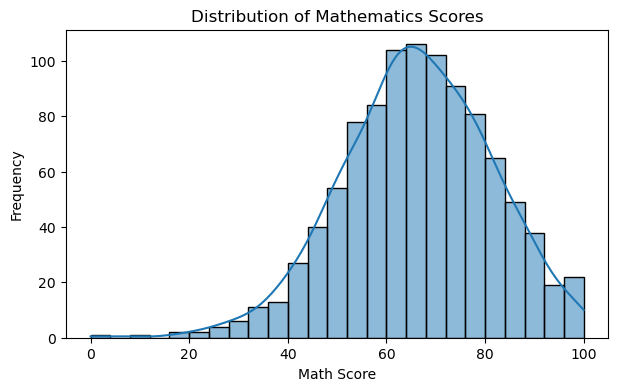

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="math score", kde=True)
plt.title("Distribution of Mathematics Scores")
plt.xlabel("Math Score")
plt.ylabel("Frequency")
plt.show()

#### *Math score by test preparation course :*

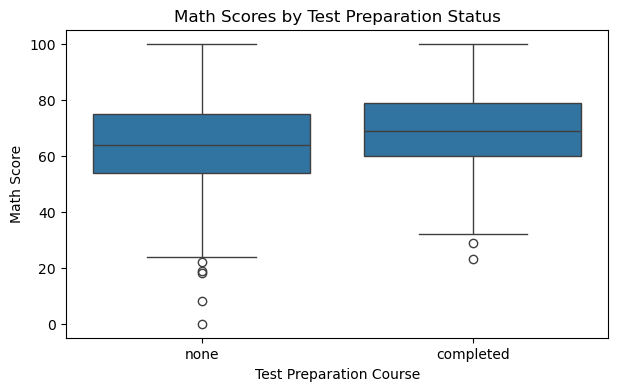

In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="test preparation course", y="math score")
plt.title("Math Scores by Test Preparation Status")
plt.xlabel("Test Preparation Course")
plt.ylabel("Math Score")
plt.show()

### 4.7 EDA Observations

- The dataset contains student information and examination scores.
- Numerical and categorical variables were identified.
- Missing values and duplicate records were checked.
- Descriptive statistics and score distributions were examined.
- The dataset is now ready for selecting suitable hypothesis tests, subject to checking their assumptions.

## **5. Hypothesis Testing :-**

Hypothesis testing is a statistical method used to evaluate a claim about a population using sample data.

It helps determine whether an observed difference or relationship is statistically significant.


### 5.1 Null and Alternative Hypotheses

- Null Hypothesis (H0): Assumes no difference or no association.
- Alternative Hypothesis (H1): Assumes a difference or an association exists.


### 5.2 Significance Level and P-Value

The significance level (α) is the threshold used to make a statistical decision. We use α = 0.05.

The p-value measures how compatible the observed result is with the null hypothesis, assuming the null hypothesis is true.

- If p-value < 0.05, reject H0.
- If p-value ≥ 0.05, fail to reject H0.


### 5.3 Type I and Type II Errors

- Type I Error: Rejecting a true null hypothesis.
- Type II Error: Failing to reject a false null hypothesis.


## **6. Independent Two-Sample t-Test :-**

### 6.1 Hypothesis Formulation

We want to compare the average mathematics scores of students who completed the test preparation course with those who did not.

- **Null Hypothesis (H₀):** Both groups have equal mean mathematics scores.
- **Alternative Hypothesis (H₁):** Both groups have different mean mathematics scores.
- **Significance Level (α):** 0.05 (5%)

### 6.2 Python implementation :

In [11]:

completed = df.loc[
    df["test preparation course"] == "completed",
    "math score"
]

not_completed = df.loc[
    df["test preparation course"] == "none",
    "math score"
]

t_stat, p_value = stats.ttest_ind(
    completed,
    not_completed,
    equal_var=False
)

alpha = 0.05

print("Completed group mean:", round(completed.mean(), 2))
print("Not completed group mean:", round(not_completed.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 6))

if p_value < alpha:
    print("Reject H0: The difference is statistically significant.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")


Completed group mean: 69.7
Not completed group mean: 64.08
T-statistic: 5.787
P-value: 0.0
Reject H0: The difference is statistically significant.


### 6.3 Result and Interpretation

The mean mathematics score of students who completed the test preparation course was 69.70, compared with 64.08 for students who did not complete the course.

The difference in means was 5.62 marks. The p-value was below the significance level of 0.05.

Therefore, we reject the null hypothesis and conclude that there is statistically significant evidence of a difference in mean mathematics scores between the two groups.

This result shows an association between test preparation status and mathematics performance; it does not establish causation.


## **7. One-Sample t-Test :-**

### 7.1 Hypothesis Formulation

We want to check whether the average mathematics score of students is significantly different from 65.

- **Null Hypothesis (H₀):** Average math score is 65.
- **Alternative Hypothesis (H₁):** Average math score is not 65.
- **Significance Level (α):** 0.05 (5%)

**Decision Rule:** If p-value < 0.05, reject H₀; otherwise, fail to reject H₀.

### 7.2 Python Implementation

In [12]:

math_scores = df["math score"]

t_stat, p_value = stats.ttest_1samp(
    math_scores,
    popmean=65
)

alpha = 0.05

print("Sample mean:", round(math_scores.mean(), 2))
print("Hypothesized population mean: 65")
print("T-statistic:", round(t_stat, 4))
print("P-value:", f"{p_value:.8f}")

if p_value < alpha:
    print("Reject H0: Mean score is significantly different from 65.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")


Sample mean: 66.09
Hypothesized population mean: 65
T-statistic: 2.2711
P-value: 0.02335169
Reject H0: Mean score is significantly different from 65.


### 7.3 Result and Interpretation

The sample mean mathematics score is 66.09, which is slightly higher than 65. The p-value (0.02335) is less than the significance level (0.05). Therefore, we reject the null hypothesis.

**Conclusion:** There is statistically significant evidence that the average mathematics score differs from 65 marks.

## **8. Paired t-Test :-**

### 8.1 Hypothesis Formulation

We want to check whether students' average reading and writing scores are significantly different.

- **Null Hypothesis (H₀):** The mean reading and writing scores are equal.
- **Alternative Hypothesis (H₁):** The mean reading and writing scores are different.
- **Significance Level (α):** 0.05 (5%)

### 8.2 Python Implementation

In [13]:
reading_scores = df["reading score"]
writing_scores = df["writing score"]

t_stat, p_value = stats.ttest_rel(
    reading_scores,
    writing_scores
)

alpha = 0.05

print("Mean Reading Score:", round(reading_scores.mean(), 2))
print("Mean Writing Score:", round(writing_scores.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", f"{p_value:.8f}")

if p_value < alpha:
    print("Reject H0: Reading and writing scores are significantly different.")
else:
    print("Fail to reject H0: No significant difference was found.")

Mean Reading Score: 69.17
Mean Writing Score: 68.05
T-statistic: 7.7874
P-value: 0.00000000
Reject H0: Reading and writing scores are significantly different.


### 8.3 Result and Interpretation

The mean reading score is 69.17, while the mean writing score is 68.05. The p-value is less than 0.05. Therefore, we reject the null hypothesis.

**Conclusion:** There is a statistically significant difference between the average reading and writing scores of students. Reading scores are higher on average than writing scores.

## **9. One-Way ANOVA :-**

### 9.1 Hypothesis Formulation

We want to check whether average mathematics scores differ across parental education levels.

- **Null Hypothesis (H₀):** The mean mathematics scores are equal across all parental education groups.
- **Alternative Hypothesis (H₁):** At least one group's mean mathematics score is different.
- **Significance Level (α):** 0.05 (5%)

### 9.2 Python Implementation

In [14]:
groups = [
    group["math score"].values
    for _, group in df.groupby("parental level of education")
]

f_stat, p_value = stats.f_oneway(*groups)

alpha = 0.05

print("F-statistic:", round(f_stat, 4))
print("P-value:", f"{p_value:.8f}")

if p_value < alpha:
    print("Reject H0: Significant differences exist between groups.")
else:
    print("Fail to reject H0: No significant difference was found.")

F-statistic: 6.5216
P-value: 0.00000559
Reject H0: Significant differences exist between groups.


### 9.3 Result and Interpretation

The ANOVA test produced an F-statistic of 6.5216 and a p-value of 0.00000559. Since the p-value is less than 0.05, we reject the null hypothesis.

**Conclusion:** There is a statistically significant difference in mean mathematics scores among parental education groups. However, further tests are needed to identify which specific groups differ.

## **10. Chi-Square Test of Independence :-**

### 10.1 Hypothesis Formulation

We want to check whether gender and test preparation course completion are associated.

- **Null Hypothesis (H₀):** Gender and test preparation course completion are independent.
- **Alternative Hypothesis (H₁):** Gender and test preparation course completion are associated.
- **Significance Level (α):** 0.05 (5%)

### 10.2 Python Implementation

In [15]:
contingency_table = pd.crosstab(
    df["gender"],
    df["test preparation course"]
)

chi2_stat, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

alpha = 0.05

print("Contingency Table:")
print(contingency_table)
print("\nChi-Square Statistic:", round(chi2_stat, 4))
print("Degrees of Freedom:", dof)
print("P-value:", f"{p_value:.8f}")

if p_value < alpha:
    print("Reject H0: Gender and test preparation are associated.")
else:
    print("Fail to reject H0: No significant association was found.")

Contingency Table:
test preparation course  completed  none
gender                                  
female                         184   334
male                           174   308

Chi-Square Statistic: 0.0155
Degrees of Freedom: 1
P-value: 0.90082739
Fail to reject H0: No significant association was found.


### 10.3 Result and Interpretation

The Chi-Square statistic is 0.0155, and the p-value is 0.90082739. Since the p-value is greater than 0.05, we fail to reject the null hypothesis.

**Conclusion:** There is insufficient statistical evidence of an association between gender and test preparation course completion.

## **11. Normality Test :-**

### 11.1 Hypothesis Formulation

We want to check whether students' mathematics scores follow a normal distribution.

- **Null Hypothesis (H₀):** The mathematics scores follow a normal distribution.
- **Alternative Hypothesis (H₁):** The mathematics scores do not follow a normal distribution.
- **Significance Level (α):** 0.05 (5%)

### 11.2 Python Implementation

In [16]:
math_scores = df["math score"]

statistic, p_value = stats.shapiro(math_scores)

alpha = 0.05

print("Shapiro-Wilk Statistic:", round(statistic, 4))
print("P-value:", f"{p_value:.8f}")

if p_value < alpha:
    print("Reject H0: Scores do not follow a normal distribution.")
else:
    print("Fail to reject H0: No significant evidence against normality.")

Shapiro-Wilk Statistic: 0.9932
P-value: 0.00014546
Reject H0: Scores do not follow a normal distribution.


### 11.3 Result and Interpretation

The Shapiro-Wilk test produced a statistic of 0.9932 and a p-value of 0.00014546. Since the p-value is less than 0.05, we reject the null hypothesis.

**Conclusion:** The mathematics scores show a statistically significant deviation from a normal distribution.

## **12. Final Conclusion :-**

This project explored the Students Performance in Exams dataset using Exploratory Data Analysis (EDA) and hypothesis testing. The dataset contained 1,000 students and 8 columns, with no missing values or duplicate records.

The independent t-test showed a significant difference in mathematics scores between students who completed the test preparation course and those who did not. The one-sample t-test found that the average mathematics score differed significantly from 65. The paired t-test showed a significant difference between reading and writing scores. One-way ANOVA found significant differences in mathematics scores across parental education groups. The Chi-Square test found no significant association between gender and test preparation course completion.

The Shapiro-Wilk test indicated that mathematics scores significantly deviated from a normal distribution at the 5% significance level.

Overall, the project demonstrated how Python can be used to explore student performance and test statistical hypotheses. These findings show statistical associations and differences, but do not establish cause-and-effect relationships.